## Descripción del problema de negocio

El lenguaje de señas es la principal forma de comunicación para la comunidad sorda. Sin embargo, la accesibilidad a servicios básicos (salud, educación, atención al cliente) sigue siendo un desafío debido a la escasez de intérpretes y de herramientas tecnológicas de apoyo. Este proyecto explora el uso de técnicas de aprendizaje profundo, específicamente un Perceptrón Multicapa (MLP), para reconocer letras individuales del alfabeto de señas, con el objetivo de sentar las bases para futuros sistemas de traducción automática de señas.

En esta segunda etapa (EP2), el proyecto evoluciona desde un Perceptrón Multicapa (MLP) hacia una Red Neuronal Convolucional (CNN). El objetivo es demostrar empíricamente cómo la capacidad de la CNN para preservar la estructura espacial de las imágenes supera las limitaciones del MLP, permitiendo una clasificación más precisa de señas visualmente similares.

## Variante

Se utilizó el dataset Sign Language MNIST disponible en Kaggle. Contiene imágenes de 28x28 píxeles en escala de grises. Variante: Se mantiene el subconjunto de 6 letras con alta similitud visual: A, E, M, N, S y T (etiquetas originales 0, 4, 12, 13, 18, 19). Esta selección se mantiene para garantizar una comparación justa y objetiva entre el modelo MLP anterior y la CNN actual, enfocándose en el desafío de discriminar puños y posiciones de dedos complejas.

## Objetivos del proyecto

1.  **Objetivo general:**
    - Diseñar, implementar y evaluar una Red Neuronal Convolucional (CNN) para la clasificación de letras del lenguaje de señas, comparando objetivamente su rendimiento y capacidad de extracción de características frente al modelo MLP desarrollado previamente.



2.  **Objetivos específicos:**
    - Mantener la variante del problema: subconjunto de 6 letras visualmente - similares (A, E, M, N, S, T) del dataset Sign Language MNIST.
    - Preparar los datos conservando la estructura matricial (28x28x1) para la CNN.
    - Diseñar una arquitectura CNN justificando sus capas convolucionales, pooling y densas.
    - Implementar técnicas de regularización (Dropout) para mitigar el sobreajuste observado en la EP1.
    - Comparar el desempeño (Accuracy, F1-Score, matrices de confusión) entre el modelo MLP y la CNN.
    - Visualizar e interpretar los mapas de características (Feature Maps) generados por las capas convolucionales

## KPIs (Indicadores Clave de Desempeño)

1.  **Precisión global (Accuracy):** Porcentaje de señas clasificadas correctamente sobre el total. Es la métrica principal del rendimiento general.
2.  **F1-Score por clase:** Especialmente crítico para las clases M, N y S, donde se espera un desempeño más bajo. Este indicador permite evaluar el equilibrio entre precisión y exhaustividad para las clases más difíciles.
3.  **Tasa de confusión entre pares (M-S, M-N, N-A):** Análisis de los errores sistemáticos más frecuentes. Este indicador cualitativo es fundamental para entender las limitaciones del modelo y guiar la elección de futuras arquitecturas o técnicas de preprocesamiento.

## Comprensión y exploración del conjunto de datos

In [ ]:
!pip install kagglehub -q

In [ ]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

Se importan las librerias necesarias para realizar el desarrollo del modelo Deep learning

In [ ]:
path = kagglehub.dataset_download("datamunge/sign-language-mnist")
train = pd.read_csv(f"{path}/sign_mnist_train.csv")
test = pd.read_csv(f"{path}/sign_mnist_test.csv")



x_train = train.drop('label', axis=1).values
y_train = train['label'].values

x_test = test.drop('label', axis=1).values
y_test = test['label'].values

letras_similares = [0, 4, 12, 13, 18, 19]

mask_train = np.isin(y_train, letras_similares)
mask_test = np.isin(y_test, letras_similares)

x_train_filtrado = x_train[mask_train]
y_train_filtrado = y_train[mask_train]

x_test_filtrado = x_test[mask_test]
y_test_filtrado = y_test[mask_test]

mapeo_clases = {clase_orig: idx for idx, clase_orig in enumerate(letras_similares)}
etiquetas_nombre = {0: 'A', 4: 'E', 12: 'M', 13: 'N', 18: 'S', 19: 'T'}

y_train_mapped = np.array([mapeo_clases[val] for val in y_train_filtrado])
y_test_mapped = np.array([mapeo_clases[val] for val in y_test_filtrado])

100%|██████████| 62.6M/62.6M [00:00<00:00, 160MB/s]

Extracting files...


In [ ]:
print(x_train.shape)
print(y_train.shape)

(27455, 784)
(27455,)


El código inicial realiza la lectura del dataset de entrenamiento y prueba, separando las variables predictoras (x_train, x_test) de las etiquetas a predecir (y_train, y_test).
Dimensiones originales: La salida nos dice que hay un total de 27,455 muestras de entrenamiento, donde cada instancia cuenta con 784 características(pixeles)  Teniendo en cuenta la naturaleza de los datos, cada fila representa una imagen aplanada de 28x28 pixeles en escala de grises del lenguaje de señas, donde cada columna almacena un valor de intensidad de píxel entre 0 y 255

Dado que las clases originales del dataset completo no se encuentran indexadas de forma secuencial algo que resulta necesario para el uso de funciones de pérdida como la Categorical Cross-Entropy o capas de salida con activación Softmax en redes neuronales, el código ejecuta dos procesos importantes:

Filtro(np.isin): Se filtran tanto el conjunto de entrenamiento como el de prueba para conservar unicamente los registros asociados a las 6 letras seleccionadas, reduciendo el espacio de busqueda a algo mas manejable para una arquitectura perceptrón multicapa

Mapeo (mapeo_clases): Tambien se implementa un diccionario de conversión que reasigna las etiquetas originales dispersas a un rango continuo y ordenado de índices de 0 a 5 (del 1 al 6 correspondientemente). Esto garantiza que la capa de salida de la red neuronal interprete correctamente las clases sin generar errores en los indices durante el cálculo del gradiente y la perdida

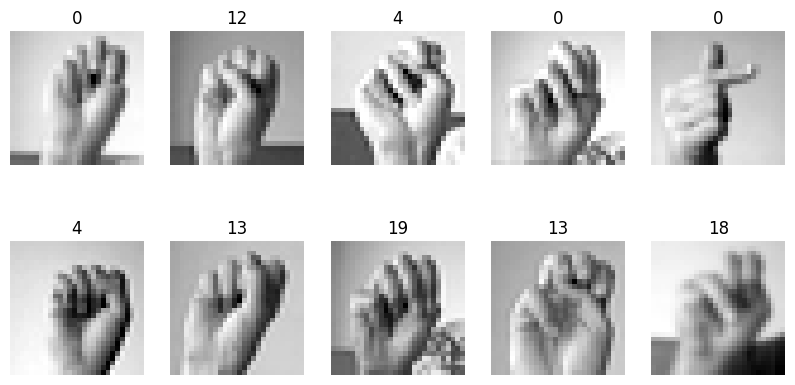

In [ ]:
fig, ax = plt.subplots(2,5,figsize = (10,5))
for i,a in enumerate(ax.ravel()):
  a.imshow(x_train_filtrado[i].reshape(28, 28), cmap="gray")
  a.set_title(y_test_filtrado[i])
  a.axis("off")
plt.show()

utilizando matplotlib para visualizar diez ejemplos representativos del conjunto de datos donde se realiza la remodelacion de vectores a matrices (28x28)

Cada instancia almacenada originalmente como un vector plano de 784 características es convertida nuevamente a su matriz espacial original mediante .reshape(28, 28) para permitir su renderizado como imagen en escala de grises

A través de la visualización nos permiten apreciar tanto las características estructurales del dataset Sign MNIST, destacando la variabilidad en la postura de la mano, la iluminación y la cercanía al encuadre, lo cual nos da entender la complejidad del problema de clasificación que a de resolver el modelo de Perceptrón Multicapa

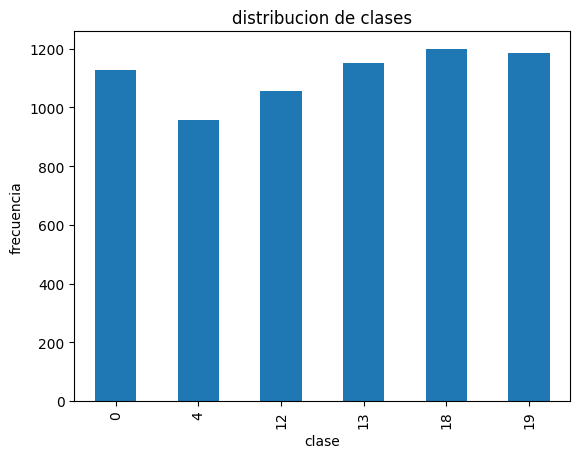

In [ ]:
pd.Series(y_train_filtrado).value_counts().sort_index().plot(kind="bar")
plt.title("distribucion de clases")
plt.xlabel("clase")
plt.ylabel("frecuencia")
plt.show()

En esta parte del codigo visualizamos la frecuencia de cada etiqueta o clase en el conjunto de entrenamiento filtrado, ordenandolo secuencialmente para mejor entendimiento

El gráfico de barras muestra las frecuencias correspondientes a las seis clases analizadas (0, 4, 12, 13, 18 y 19). Se observa una distribución relativamente equilibrada entre las categorías, donde cada una ronda aproximadamente entre las 950 y 1,200 muestras de entrenamiento

Este equilibrio es un factor a tomar en cuenta para el aprendizaje de un Perceptrón Multicapa (MLP). Al no existir un desbalance severo de clases (clases mayoritarias que dominen el entrenamiento frente a otras con muy pocos registros), se reduce el riesgo de que el modelo sufra de sesgos predictivos importantes hacia una categoría en particular, permitiendo que las métricas globales como el Accuracy reflejen el desempeño real de la red neuronal

## preparacion de datos

In [ ]:
x_train = x_train_filtrado / 255.0
x_test = x_test_filtrado / 255.0


y_train_cat = to_categorical(y_train_mapped, num_classes=6)
y_test_cat = to_categorical(y_test_mapped, num_classes=6)

x_tr, x_val, y_tr, y_val = train_test_split(
    x_train,
    y_train_cat,
    test_size=0.2,
    random_state=123,
    stratify=y_train_cat
)

x_tr_cnn = x_tr.reshape(-1, 28, 28, 1)
x_val_cnn = x_val.reshape(-1, 28, 28, 1)
x_test_cnn = x_test.reshape(-1, 28, 28, 1)

print(f"Forma Train CNN: {x_tr_cnn.shape}")
print(f"Forma Val CNN: {x_val_cnn.shape}")
print(f"Forma Test CNN: {x_test_cnn.shape}")


Forma Train CNN: (5339, 28, 28, 1)
Forma Val CNN: (1335, 28, 28, 1)
Forma Test CNN: (2008, 28, 28, 1)


In [ ]:
x_train.shape

(6674, 784)

**Preparación de datos para la CNN**

Este bloque de código se encarga de normalizar las imágenes, codificar las etiquetas, dividir el conjunto de entrenamiento para validación y adaptar la forma de los tensores para la red neuronal convolucional.

**Normalizacion de datos:**

Por un lado se divide todos los valores de los píxeles de las imágenes (que originalmente van de 0 a 255) entre 255.0.
Lo que permite escalar los datos al rango 0 y 1. Esto es fundamental en Deep Learning porque facilita la convergencia del algoritmo de optimización (como Adam o SGD), evitando que valores grandes de píxeles saturen las funciones de activación y acelerando el entrenamiento por descenso de gradiente

**Codificacion de etiquetas(one-hot):**

Tambien se convierte las etiquetas numéricas de las clases (por ejemplo, números enteros de 0 a 5 para las 6 clases) en vectores binarios de tipo one-hot encoding
ya que las capas de salida de las CNNs con clasificación multiclase suelen usar una función de activación softmax que emite probabilidades para cada una de las clases. Para calcular la pérdida (loss) mediante entropía cruzada categórica (categorical crossentropy), las etiquetas reales deben tener la misma estructura vectorial.

**Division de datos de entrenamiento y validacion:**

Se parte el conjunto de entrenamiento en dos subconjuntos: uno para entrenar (80%) y otro para validar (20%)

Ademas, se hizo uso de stratify para asegurar que la proporción de cada una de las 6 clases sea idéntica tanto en el conjunto de entrenamiento como en el de validación, previniendo sesgos por desbalanceo de clases
tambien se fija la una semilla aleatoria para asegurar la reproducibilidad de los resultados en cada ejecución

**Adaptación dimensional para la CNN**

Por ultimo adaptamos las dimensiones de los datos. Ya que las imágenes originalmente estaban aplanadas como vectores de 784 características ((6674, 784) debido a matrices de 28x28). El método reshape las reconstruye a una estructura de 4 dimensiones requerida por las capas Conv2D: (número_de_muestras, alto, ancho, canales).

Cada valor indicaria lo siguiente:

-1: Calcula automáticamente el número total de muestras disponibles.

28, 28: Define el alto y ancho espacial de la imagen en formato matricial para que los filtros convolucionales puedan aplicar operaciones espaciales (kernel).

1: Indica el número de canales de color. En este caso es 1 porque las imágenes son en escala de grises (si fueran RGB, sería 3)

## Modelo Base

In [ ]:
def graficar_historial(history, titulo):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))


    ax1.plot(history.history['loss'], label='Train Loss')
    ax1.plot(history.history['val_loss'], label='Val Loss')
    ax1.set_title(f'Pérdida - {titulo}')
    ax1.set_xlabel('Época')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)


    ax2.plot(history.history['accuracy'], label='Train Acc')
    ax2.plot(history.history['val_accuracy'], label='Val Acc')
    ax2.set_title(f'Precisión - {titulo}')
    ax2.set_xlabel('Época')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

In [ ]:
def evaluar_modelo_completo(model, history, x_test, y_test_cat, titulo):
    graficar_historial(history, titulo)

    y_pred_probs = model.predict(x_test, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = np.argmax(y_test_cat, axis=1)
    test_loss, test_acc = model.evaluate(x_test, y_test_cat, verbose=0)

    print(f"\n================ RESUMEN DE EVALUACIÓN: {titulo} ================")
    print(f"Test Accuracy:        {test_acc * 100:.2f}%")
    print(f"Test Loss:            {test_loss:.4f}")
    print(f"=================================================================\n")


    nombres_letras = ['A', 'E', 'M', 'N', 'S', 'T']
    print(classification_report(y_true, y_pred, target_names=nombres_letras))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=nombres_letras, yticklabels=nombres_letras)
    plt.xlabel('Predicción del Modelo')
    plt.ylabel('Clase Real')
    plt.title(f'Matriz de Confusión - {titulo}')
    plt.show()

Realizamos 2 funciones especificas que nos permitiran automatizar los procesos de registro de modelos y ver su desempeño por un lado:

La función graficar_historial automatiza el registro y la representación gráfica del proceso de aprendizaje de la red neuronal a lo largo de las epocas, nos permite graficar de forma simultánea la evolución de la función de pérdida tanto para el conjunto de entrenamiento, como para el de validación. Permite identificar la convergencia del optimizador y detectar de manera temprana signos de sobreajuste (overfitting), el cual se manifiesta cuando la pérdida de entrenamiento sigue disminuyendo mientras la de validación comienza a incrementarse
Luego esta el grafico de Precisión, que compara la precisión obtenida en los datos de entrenamiento frente a los de validación en cada una de las epocas. facilitando la visualización de la estabilidad del aprendizaje y el porcentaje maximo de acierto alcanzado por el modelo MLP

Luego tenemos la funcion para evaluar los desempeños de los distintos modelos de forma automatiza y eficiente:

La función evaluar_modelo_completo encapsula la fase de prueba sobre los datos, calculando y reportando las métricas e interpretaciones gráficas

1. Para la inferencia y conversión de Probabilidades, obtenemos un lista de probabilidades para cada una de las 6 clases de salida calculando cada uno de sus metricas individualmente

    Tambien convierte las probabilidades de la capa Softmax (tanto en las predicciones como en las etiquetas categoricas reales) de vuelta a indices enteros o sus etiquetas reales. Esto permite alinear las predicciones de la red con las etiquetas verdaderas para el calculo de metricas vectorizadas

2. Métricas Globales (Accuracy y Loss de Prueba): Calculamos de forma independiente la pérdida final (Test Loss) y la precisión global (Test Accuracy) del modelo sobre el conjunto de pruebas no visto. Dandonos un valor porcentual para saber la efectividad general del modelo para reconocer correctamente las señas de las letras A, E, M, N, S y T

3. Para el reporte de metricas, utilizamos una lista con los nombres reales de las clases (['A', 'E', 'M', 'N', 'S', 'T']) para calcular metricas avanzadas por categoría ya sea tanto la Precision (Precisión) que es la proporción de predicciones positivas verdaderas frente al total de predicciones positivas realizadas para cada seña, midiendo cuántos falsos positivos genera el modelo

    Tambien calculamos el Recall que mide la capacidad de la red para identificar correctamente todas las instancias reales de cada clase, cuantificando los falsos negativos

    Y por ultimo el F1-Score que calcula la media entre Precision y Recall, entregando una metrica equilibrada fundamental cuando se analizan clases que comparten similitudes visuales complejas dentro de las imagenes de señas

4. Y por ultimo para el analisis generamos una matriz de confusión visual en formato de mapa de calor utilizando una paleta que nos permite identificar de manera grafica que letras especificas generan mayor nivel de confusion en el modelo debido a la similitud que estan puedan tener, logrando asi un analisis critico de errores y limitaciones de la red neuronal en el procesamiento de estas imagenes

In [ ]:
model_cnn = Sequential([

    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),


    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),


    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(6, activation='softmax')
])

model_cnn.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,670 (475.27 KB)

 Trainable params: 121,670 (475.27 KB)

 Non-trainable params: 0 (0.00 B)

Este bloque define la arquitectura secuencial de la Red Neuronal Convolucional utilizando Keras. Su objetivo principal es extraer automáticamente características espaciales jerárquicas de las imágenes (desde bordes y líneas simples en las primeras capas hasta formas más complejas en las profundas) y realizar la clasificación final en 6 categorías distintas.

**1. Primera etapa de extracción de características (Bloque Convolucional 1)**

Se aplican 32 filtros convolucionales de tamaño 3x3 sobre la imagen de entrada.

Utiliza la función de activación ReLU para introducir no linealidad y permitir que la red aprenda patrones complejos.
El parámetro input_shape=(28, 28, 1) le indica a la red que recibirá imágenes de 28x28 píxeles con 1 solo canal (escala de grises).

Luego se utiliza un Pooling que aplica una operación de submuestreo con una ventana de 2x2. Lo que reduce a la mitad las dimensiones espaciales de la matriz, disminuyendo el costo computacional y ayudando a retener las características más relevantes.

**2. Segunda etapa de extracción de características (Bloque Convolucional 2)**

Pasando a la segunda convulicion, se duplica la capacidad de abstracción utilizando 64 filtros de 3x3. Al ser mas profunda la red, combina las características básicas de la primera capa y a su vez extrae patrones más complejos de las imagenes o del objeto.
Tambien se hace uso de Pooling que vuelve a reducir las dimensiones espaciales mediante el valor máximo local, compactando aún más la representación antes de pasar a la fase densa.

**3. Fase de clasificación (Capas Densas y Regularización)**

Aplaana la salida de 3D de las matrices convolucionales anteriores transformándola en un vector unidimensional largo. Esto es necesario para conectar las características extraídas con las capas densas tradicionales (Fully Connected).

Dense(64, activation='relu'): Una capa totalmente conectada de 64 neuronas con activación ReLU que interpreta las características aplanadas y comienza a tomar decisiones lógicas sobre la categoría de la imagen.

Dropout(0.5): Capa de regularización que apaga aleatoriamente el 50% de las conexiones durante el entrenamiento, forzando a la red a no depender de neuronas específicas y a generalizar mejor. Esta fue una decision clave ya que se añadió para combatir el sobreajuste severo detectado en la primera etapa

Dense(6, activation='softmax'): Capa de salida con 6 neuronas (una para cada clase del problema). La función de activación softmax convierte los valores de salida en probabilidades que suman 1 (100%), permitiendo identificar a qué clase pertenece la imagen con mayor certeza.

El resumen de la arquitectura muestra un modelo con un total de 121,670 parámetros entrenables. Las capas convolucionales y de max pooling reducen progresivamente las dimensiones espaciales de las imágenes de entrada mientras incrementan los mapas de características hasta llegar a una forma aplanada de 1,600 valores. Finalmente, una capa densa de 64 neuronas con dropout procesa la información y una capa de salida densa con activación softmax genera la clasificación final en 6 categorías distintas.

In [ ]:
model_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


early_stop_cnn = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_cnn = model_cnn.fit(
    x_tr_cnn, y_tr,
    epochs=50,
    batch_size=64,
    validation_data=(x_val_cnn, y_val),
    callbacks=[early_stop_cnn]
)

Epoch 1/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.2746 - loss: 1.7131 - val_accuracy: 0.4831 - val_loss: 1.4391
Epoch 2/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.4973 - loss: 1.2379 - val_accuracy: 0.7775 - val_loss: 0.8206
Epoch 3/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.6966 - loss: 0.7940 - val_accuracy: 0.8742 - val_loss: 0.4523
Epoch 4/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.8134 - loss: 0.5161 - val_accuracy: 0.9738 - val_loss: 0.2281
Epoch 5/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.8739 - loss: 0.3523 - val_accuracy: 0.9880 - val_loss: 0.1079
Epoch 6/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9107 - loss: 0.2586 - val_accuracy: 0.9903 - val_loss: 0.0677
Epoch 7/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.9241 - loss: 0.2086 - val_accuracy: 0.9970 - val_loss: 0.0393
Epoch 8/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9404 - loss: 0.1675 - val_accuracy: 0.9985 - v

Este bloque prepara el modelo para aprender, configura un mecanismo de seguridad para detener el entrenamiento si el modelo deja de mejorar (evitando sobreajuste) y ejecuta el proceso iterativo donde la red ajusta sus pesos internos a lo largo de 50 épocas utilizando los datos de entrenamiento y validación

**Justificación de hiperparámetros:** Se utilizó el optimizador Adam (learning rate=0.001) y batch size de 64, basándose en los resultados óptimos obtenidos durante la primera parte del modelo MLP. Se usó EarlyStopping (paciencia=10) para detener el entrenamiento si la pérdida de validación dejaba de mejorar

**1. Compilación del modelo**

Utiliza el optimizador Adam (Adaptive Moment Estimation), un algoritmo eficiente de descenso de gradiente que ajusta automáticamente la tasa de aprendizaje para cada parámetro, logrando una convergencia rápida y estable.

Tambien se define la función de pérdida(categorical_crossentropy) para evaluar qué tan equivocadas están las predicciones de la red frente a las etiquetas reales. Es la métrica estándar para problemas de clasificación multiclase.

Por ultimo se configura la métrica de control que se evaluará en cada época, midiendo el porcentaje de imágenes clasificadas correctamente.

**2. Configuración de Early Stopping**

Actúa como un supervisor del entrenamiento. Monitorea la pérdida en la validación (val_loss). Si durante 10 épocas consecutivas (patience=10) esta pérdida no mejora, el entrenamiento se detiene de manera automáticamente.
Garantiza que, al detenerse, el modelo recupere y conserve los pesos exactos de la época que obtuvo el mejor resultado de validación, evitando que empeore si empieza a sobreajustarse al final.

**3. Ejecución del Entrenamiento (Fit)**

Por ultimo se pasaria a la fase de entrenamiento,donde se establece el límite máximo de pasadas completas que el modelo hará sobre todo el conjunto de entrenamiento siendo de 50 epocas.

Se define un tamaño de lotes que se procesarán en bloques de 64 en 64 antes de actualizar los pesos de la red.

Tambien se evaluara el desempeño del modelo con el conjunto de validación (x_val_cnn, y_val) al final de cada época para medir su capacidad de generalización. Junto con esto se integra la regla del early stopping en el bucle de entrenamiento.

Viendo el proceso de entremiento por el cual fue sometido el modelo mediante su salida, es posible evidenciar lo siguiente:

El entrenamiento completó las 50 épocas especificadas (el Early Stopping no llegó a cortar antes porque la pérdida de validación continuó registrando variaciones o se mantuvo estable). Cada época tomó en promedio entre 3 y 5 segundos para procesar los 64 lotes de datos

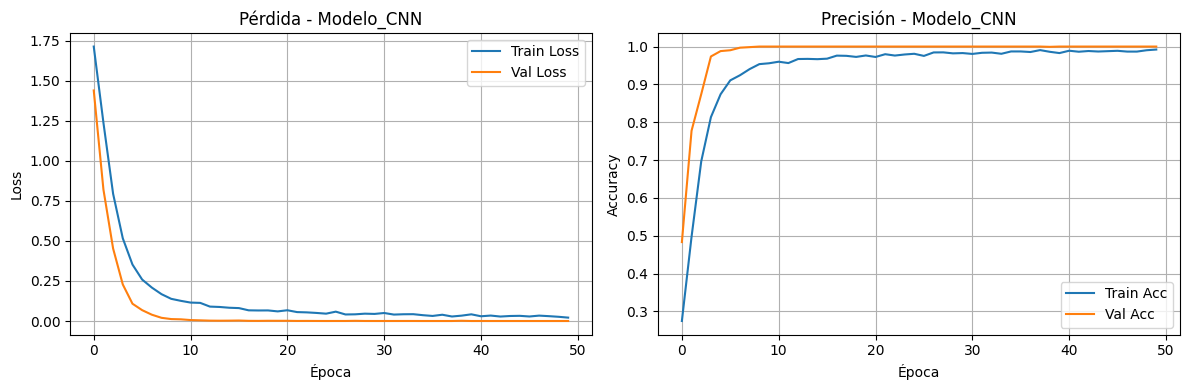


================ RESUMEN DE EVALUACIÓN: Modelo_CNN ================
Test Accuracy:        94.42%
Test Loss:            0.6847

              precision    recall  f1-score   support

           A       0.96      1.00      0.98       331
           E       0.99      0.94      0.97       498
           M       0.95      0.93      0.94       394
           N       1.00      0.81      0.89       291
           S       0.83      1.00      0.91       246
           T       0.92      1.00      0.96       248

    accuracy                           0.94      2008
   macro avg       0.94      0.95      0.94      2008
weighted avg       0.95      0.94      0.94      2008



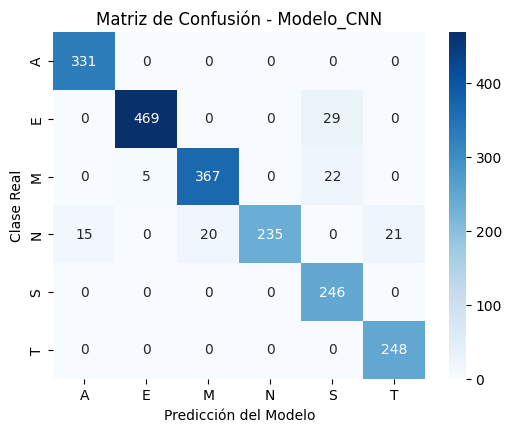

In [ ]:
evaluar_modelo_completo(model_cnn, history_cnn, x_test_cnn, y_test_cat, "Modelo_CNN")

**Evaluacion del Modelo entrenado:**

Este bloque evalúa el rendimiento general y detallado del modelo ya entrenado. Su objetivo es comprobar la capacidad de generalización de la CNN mediante curvas de aprendizaje, métricas globales (accuracy, loss), un reporte de clasificación por clase (precision, recall, f1-score) y una matriz de confusión visual

**1. Curvas de Aprendizaje (Pérdida y Precisión)**

Observando las Gráficas de Pérdida y Precisión:

Por un lado la grafica de Pérdida (Loss). Muestra cómo la pérdida de entrenamiento (Train Loss) y de validación (Val Loss) descienden de forma suave y convergente hacia cero a medida que avanzan las épocas, lo que indicaria que el proceso de optimización fue exitoso y converge de manera correcta sin tener oscilaciones bruscas evidentes durante el proceso.

En la grafica de Precisión (Accuracy): Nos evidencia que tanto en entrenamiento como en validación la precisión escala optimamente por encima del 90% en las primeras 10 épocas hasta estabilizarse cerca del 100%, sin indicios severos de un sobreajuste (overfitting).

**2. Resumen Numérico y Métricas por Clase**

Ahora pasando al Reporte de Clasificación de las metricas podemos ver:

La precision Global del Test, obtuvo una precisión general del 94.42% sobre las imágenes de prueba, con una pérdida de prueba de 0.6847.

Por otro lado analizando las metricas por clases (Precision, Recall, F1-score):

La Clase A Mostro un excelente desempeño con un f1-score de 0.98 (331 muestras correctas). Clase E obtuvo una muy alta precisión (0.99) y un f1-score de 0.97 (498 muestras). Clase M, tuvo un rendimiento solido con un f1-score de 0.94 (394 muestras). La Clase N presenta una precisión sospechosamente perfecta, aunque un recall menor (0.81), lo que indica que algunas muestras reales de esta letra fueron clasificadas erróneamente en otras categorías algo que es posible evidenciar si se mira la matris de confusicion

Y por ultimo las Clase S y T, Destacan con un recall perfecto de 1.00 y f1-scores de 0.91 y 0.96 respectivamente.

**3. Matriz de Confusión**

Pasando a la matris de confusion esta nos permite visualizar de forma gráfica dónde acierta y dónde se equivoca el modelo. La diagonal principal muestra los aciertos absolutos por letra en los cuales realmente el modelo predice correctamente.
A su vez se observa que el mayor margen de error ocurre en la letra N, donde 15 muestras fueron confundidas con la A y 20 con la M, así como algunos cruces menores entre las letras E y M con la S, lo cual resulta comprensible debido a las similitudes visuales en las señas de manos de dichos caracteres en escala de grises, donde al modelo le resulta complicado buscar patrones distiguibles entre cada uan de las señas de manos.

# Comparación entre MLP y CNN

| Característica | MLP (EP1) | CNN (EP2) | Mejora / Análisis |
| :--- | :--- | :--- | :--- |
| **Test Accuracy** | 81.82% | 94.42% | +12.60%. Salto significativo en el rendimiento global. |
| **F1-Score (Clase M)** | 0.81 | 0.94 | La CNN entiende mucho mejor la forma del puño. |
| **F1-Score (Clase N)** | 0.63 | 0.89 | Se resolvió gran parte de la confusión histórica con la letra A. |
| **F1-Score (Clase S)** | 0.59 | 0.91 | Mejora drástica en la detección de esta clase compleja. |
| **Estructura de entrada** | Vector aplanado (784) | Matriz (28x28x1) | La CNN preserva con éxito la relación espacial y vecindad de píxeles. |
| **Overfitting** | Severo (Train 100% / Test 81%) | Controlado | Las capas de Dropout y Pooling regularizan eficazmente la red. |

La CNN supera ampliamente al MLP. Mientras el MLP sufría para diferenciar las letras M, N y S (F1-Scores entre 0.59 y 0.81), la CNN logró elevarlos por encima de 0.89. Esto se debe a que los filtros convolucionales son capaces de extraer características locales (como la curvatura de un dedo o el espacio entre ellos), mientras que el MLP solo ve intensidades globales de píxeles.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step


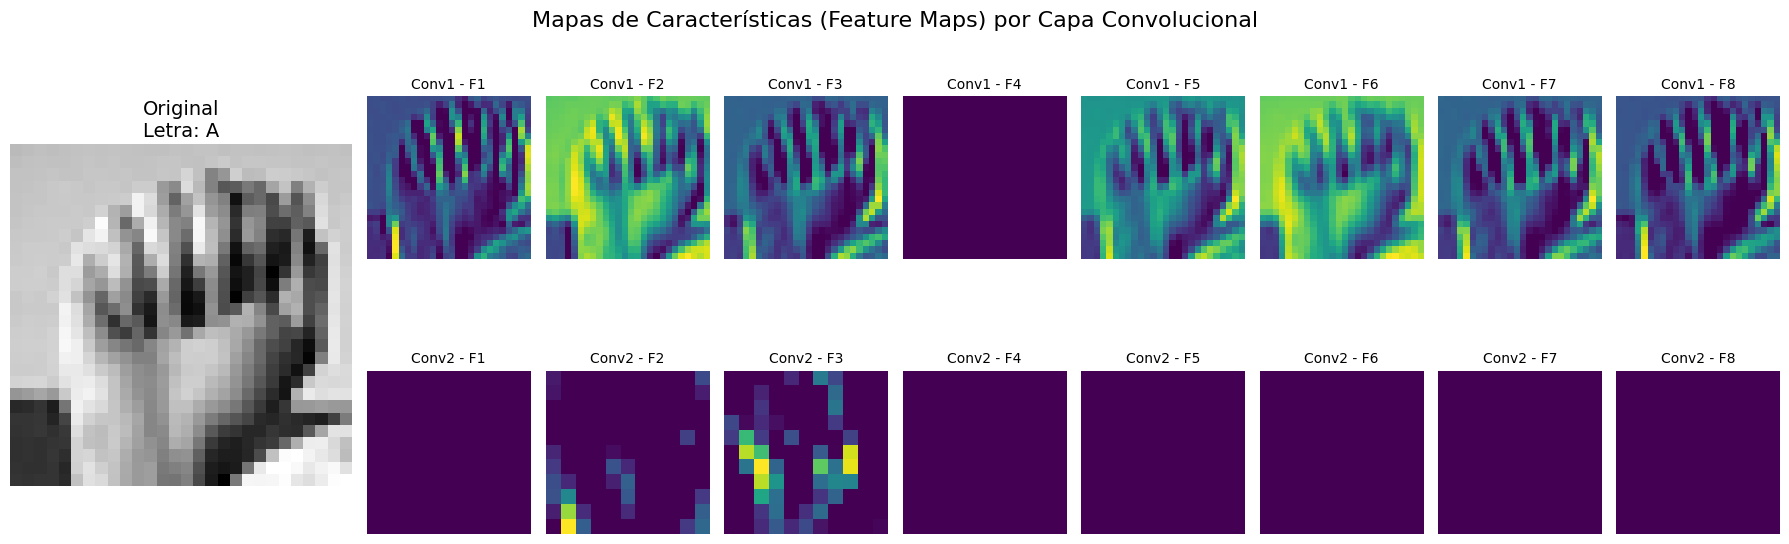

Valor máximo de activación en Conv1: 2.0476608276367188
Valor máximo de activación en Conv2: 6.948564529418945


In [ ]:
nombres_letras = ['A', 'E', 'M', 'N', 'S', 'T']
dummy_input = np.zeros((1, 28, 28, 1))
_ = model_cnn.predict(dummy_input, verbose=0)

layer_outputs = [layer.output for layer in model_cnn.layers[:4]]
activation_model = tf.keras.models.Model(inputs=model_cnn.inputs, outputs=layer_outputs)

idx_imagen = 0
img_tensor = x_test_cnn[idx_imagen:idx_imagen+1]
activaciones = activation_model.predict(img_tensor)
etiqueta_real = nombres_letras[np.argmax(y_test_cat[idx_imagen])]

fig = plt.figure(figsize=(18, 6))

ax1 = plt.subplot2grid((2, 10), (0, 0), rowspan=2, colspan=2)
ax1.imshow(x_test_cnn[idx_imagen].reshape(28, 28), cmap='gray')
ax1.set_title(f"Original\nLetra: {etiqueta_real}", fontsize=14)
ax1.axis('off')

for i in range(8):
    ax = plt.subplot2grid((2, 10), (0, i+2))
    ax.imshow(activaciones[0][0, :, :, i], cmap='viridis')
    ax.set_title(f"Conv1 - F{i+1}", fontsize=10)
    ax.axis('off')

for i in range(8):
    ax = plt.subplot2grid((2, 10), (1, i+2))
    ax.imshow(activaciones[2][0, :, :, i], cmap='viridis')
    ax.set_title(f"Conv2 - F{i+1}", fontsize=10)
    ax.axis('off')

plt.suptitle("Mapas de Características (Feature Maps) por Capa Convolucional", fontsize=16)
plt.tight_layout()
plt.show()


print(f"Valor máximo de activación en Conv1: {np.max(activaciones[0])}")
print(f"Valor máximo de activación en Conv2: {np.max(activaciones[2])}")

Este bloque extrae y grafica el funcionamiento interno de la red neuronal al procesar una imagen específica (en este caso, la letra A). Permite "abrir la caja negra" del modelo para observar qué detectan los filtros convolucionales de la primera (Conv1) y la segunda (Conv2) capa, mostrando visualmente cómo se descomponen los trazos, bordes y formas de la mano.

Se observa la seña de la Letra A del conjunto de datos de Lenguaje de Señas (Sign Language MNIST).
Fila Superior (Conv1 - F1 a F8): Los mapas de características de la primera capa muestran que los filtros capturan de forma general la silueta completa de la mano, los dedos y los contrastes de luz y sombra de la imagen original. El valor máximo de activación alcanzado en esta capa fue de 2.0476.

Fila Inferior (Conv2 - F2, F3, etc.): En la segunda capa convolucional, la información se vuelve más abstracta y localizada. Se aprecian activaciones específicas en ciertos bordes o regiones clave de los nudillos y contornos, mientras que otros filtros se desactivan por completo (se ven de color morado , como F1, F4, F5, etc.), lo que nos podria indicar que se especializan en detectar patrones distintos que no están presentes en esta imagen en particular. El valor máximo de activación subió a 6.9485, reflejando una respuesta más fuerte y especializada en las capas profundas de la red.

Conclusión de los Feature Maps: Se demuestra la jerarquía del aprendizaje profundo: las primeras capas ven "bordes" y las capas profundas buscan "conceptos" (formas de dedos).

## Análisis detallado de los errores

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
Total de aciertos: 1896
Total de errores: 112


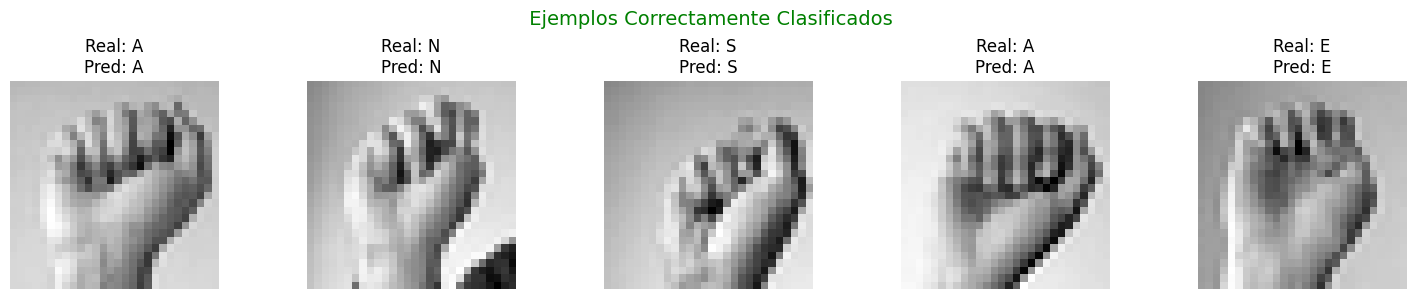

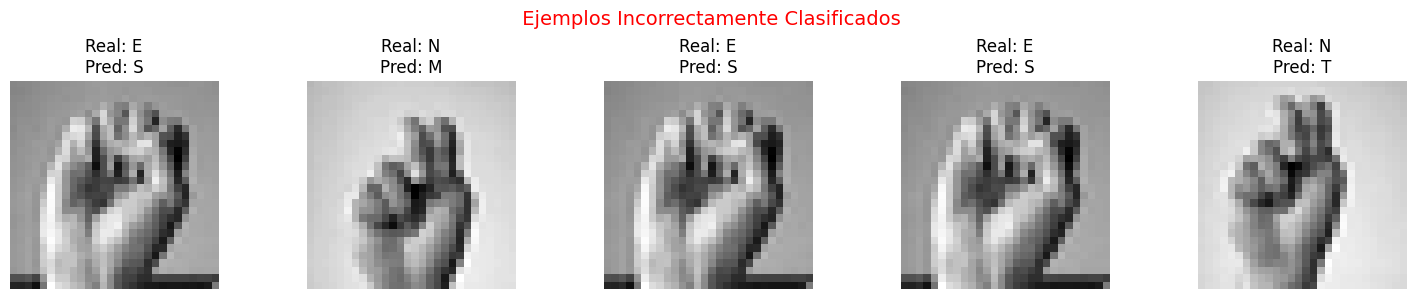

In [ ]:
y_pred_probs = model_cnn.predict(x_test_cnn)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test_cat, axis=1)


nombres_letras = ['A', 'E', 'M', 'N', 'S', 'T']


correct_idx = np.where(y_pred == y_true)[0]
incorrect_idx = np.where(y_pred != y_true)[0]

print(f"Total de aciertos: {len(correct_idx)}")
print(f"Total de errores: {len(incorrect_idx)}")


n_muestras = 5
muestras_correctas = np.random.choice(correct_idx, n_muestras, replace=False)
muestras_errores = np.random.choice(incorrect_idx, n_muestras, replace=False)


def mostrar_predicciones(indices, titulo, color_titulo='black'):
    fig, axes = plt.subplots(1, len(indices), figsize=(15, 3))
    fig.suptitle(titulo, fontsize=14, color=color_titulo)
    for i, idx in enumerate(indices):
        img = x_test[idx].reshape(28, 28)
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f'Real: {nombres_letras[y_true[idx]]}\nPred: {nombres_letras[y_pred[idx]]}')
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

# 6. Mostrar ejemplos
mostrar_predicciones(muestras_correctas, ' Ejemplos Correctamente Clasificados', 'green')
mostrar_predicciones(muestras_errores, ' Ejemplos Incorrectamente Clasificados', 'red')

## Conclusiones